# Notebook 5 — Supervised Credit-Risk Modeling

## Purpose

Compare a Logistic Regression baseline with Random Forest and a boosted-tree model for `target_default_within_12m` (1 = default within 12 months; 0 = no default). This notebook creates reproducible stratified train/validation/test splits, tunes on training data with cross-validation, uses validation for model and threshold selection, assesses probability calibration, and evaluates the test set only after all choices are frozen.

Every learned imputer, scaler, and encoder is fitted inside the training pipeline. The selected, calibrated fitted pipeline and its validation-selected classification threshold are saved to `models/credit_risk_model.joblib`.

**Scope and limitations:** These rows are synthetic. This experiment is not a lending decision engine. Predictor availability at decision time must be confirmed. In particular, existing loan terms and debt-to-income after the proposed loan may be post-decision. An available default/credit score is not a causal explanation, fairness assessment, or demonstration of production readiness.

## 1. Load the data, define model inputs, and reserve the test set

Use the same documented, timing-aware feature definitions as Notebook 3. Keep the validated monthly debt-to-income ratio and add requested loan principal divided by annualized net income. Exclude the target and ID, the EAD duplicate, the unverified LGD assumption, prior-default history with an undocumented observation window, and repayment method with undocumented timing. Split before fitting any imputer, scaler, encoder, or model.

In [1]:
from pathlib import Path
import importlib.util
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    log_loss,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import GridSearchCV, ParameterGrid, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42
TARGET = "target_default_within_12m"
relative_data_path = Path("data/raw/finsight_ai_india_synthetic_5000.csv")
data_path = next(
    (path for path in (relative_data_path, Path("..") / relative_data_path) if path.exists()),
    None,
)
if data_path is None:
    raise FileNotFoundError(
        "Could not find data/raw/finsight_ai_india_synthetic_5000.csv. "
        "Run this notebook from the project root or notebooks/ directory."
    )

df = pd.read_csv(data_path)
if TARGET not in df:
    raise ValueError(f"Expected target column {TARGET!r} is missing.")
if df[TARGET].isna().any() or not df[TARGET].isin([0, 1]).all():
    raise ValueError("The target must be complete and contain only labels 0 and 1.")
if df["monthly_net_income_inr"].isna().any() or df["monthly_net_income_inr"].le(0).any():
    raise ValueError("Positive, complete monthly net income is required for the defined ratio feature.")

numeric_features = [
    "age_years", "employment_years", "monthly_net_income_inr",
    "existing_monthly_debt_inr", "requested_loan_amount_inr", "loan_tenure_months",
    "annual_interest_rate_pct", "estimated_emi_inr", "debt_to_income_after_loan",
    "credit_history_years", "open_credit_accounts", "credit_inquiries_last_6m",
    "late_payments_last_12m", "credit_utilization_ratio", "savings_balance_inr",
    "banking_relationship_months", "dependents_count",
]
engineered_features = ["requested_loan_to_annual_income"]
categorical_features = [
    "state", "city_tier", "employment_type", "education_level", "residence_type", "loan_purpose",
]
excluded_fields = {
    "application_id": "record identifier",
    TARGET: "outcome label; never a model input",
    "prior_default_flag": "observation window is undocumented",
    "repayment_method": "may be post-application; timing is undocumented",
    "ead_assumption_inr": "duplicates requested_loan_amount_inr",
    "lgd_assumption": "unverified loss assumption, not a borrower feature",
}
raw_features = numeric_features + categorical_features
missing_columns = set(raw_features + list(excluded_fields)).difference(df.columns)
if missing_columns:
    raise ValueError(f"Expected source fields are missing: {sorted(missing_columns)}")
if set(raw_features).intersection(excluded_fields):
    raise ValueError("A target, identifier, or excluded field entered the predictor list.")

X = df[raw_features].copy()
X["requested_loan_to_annual_income"] = (
    df["requested_loan_amount_inr"] / (12 * df["monthly_net_income_inr"])
)
feature_columns = numeric_features + engineered_features + categorical_features
X = X[feature_columns]
y = df[TARGET].astype("int8")

# Reproduce the 70/15/15 stratified split used in Notebook 3 (seed 42).
X_development, X_test, y_development, y_test = train_test_split(
    X, y, test_size=0.15, random_state=RANDOM_STATE, stratify=y
)
X_train, X_validation, y_train, y_validation = train_test_split(
    X_development,
    y_development,
    test_size=(0.15 / 0.85),
    random_state=RANDOM_STATE,
    stratify=y_development,
)
assert X_train.index.intersection(X_validation.index).empty
assert X_train.index.intersection(X_test.index).empty
assert X_validation.index.intersection(X_test.index).empty

# A single preprocessing definition is cloned into each candidate estimator.
numeric_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("scaler", StandardScaler()),
    ]
)
categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="constant", fill_value="__MISSING__")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]
)
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features + engineered_features),
        ("categorical", categorical_pipeline, categorical_features),
    ],
    remainder="drop",
    sparse_threshold=0,
    verbose_feature_names_out=True,
)

print(f"Data: {len(df):,} rows; positive target rate: {y.mean():.2%}")
print(f"scikit-learn: {sklearn.__version__}; XGBoost installed: {importlib.util.find_spec('xgboost') is not None}")
split_summary = pd.DataFrame(
    {
        "rows": [len(y_train), len(y_validation), len(y_test)],
        "defaults": [int(y_train.sum()), int(y_validation.sum()), int(y_test.sum())],
        "default_rate_percent": [100 * y_train.mean(), 100 * y_validation.mean(), 100 * y_test.mean()],
    },
    index=["Training", "Validation", "Test"],
)
display(split_summary.round(2))
print("\nExcluded fields:")
display(pd.Series(excluded_fields, name="reason"))

Data: 5,000 rows; positive target rate: 27.68%
scikit-learn: 1.9.1; XGBoost installed: False


,rows,defaults,default_rate_percent
Training,3500,968,27.66
Validation,750,208,27.73
Test,750,208,27.73



Excluded fields:


application_id                                               record identifier
target_default_within_12m                   outcome label; never a model input
prior_default_flag                          observation window is undocumented
repayment_method               may be post-application; timing is undocumented
ead_assumption_inr                        duplicates requested_loan_amount_inr
lgd_assumption               unverified loss assumption, not a borrower fea...
Name: reason, dtype: str

The target is moderately imbalanced, so every split is stratified to preserve outcome prevalence. The test partition is separated before any model is trained and will remain unused until the final evaluation. Missing values are handled by pipeline steps, not by dropping applications. XGBoost is included only if the optional package is already available; otherwise the comparison uses scikit-learn's built-in histogram gradient boosting without introducing an undeclared package dependency.

## 2. Tune candidate models on training data

Use identical preprocessing and fixed, stratified three-fold cross-validation to tune Logistic Regression, Random Forest, and a boosted-tree candidate. Average precision is the tuning objective because it focuses on the positive class under imbalance. The validation and test partitions are not used in cross-validation or hyperparameter search.

In [2]:
from sklearn.base import clone

if importlib.util.find_spec("xgboost") is not None:
    from xgboost import XGBClassifier

    boosted_name = "XGBoost"
    boosted_estimator = XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        n_estimators=180,
        random_state=RANDOM_STATE,
        n_jobs=1,
        verbosity=0,
    )
    boosted_grid = {
        "model__max_depth": [2, 4],
        "model__learning_rate": [0.05, 0.1],
        "model__subsample": [0.8],
        "model__colsample_bytree": [0.8],
    }
else:
    boosted_name = "Histogram Gradient Boosting (scikit-learn)"
    boosted_estimator = HistGradientBoostingClassifier(
        random_state=RANDOM_STATE,
        early_stopping=False,
    )
    boosted_grid = {
        "model__max_iter": [120, 200],
        "model__learning_rate": [0.05, 0.1],
        "model__max_leaf_nodes": [15, 31],
        "model__l2_regularization": [1.0],
    }

candidates = {
    "Logistic Regression": (
        LogisticRegression(max_iter=2_000, solver="lbfgs", random_state=RANDOM_STATE),
        {
            "model__C": [0.1, 1.0, 10.0],
            "model__class_weight": [None, "balanced"],
        },
    ),
    "Random Forest": (
        RandomForestClassifier(
            n_estimators=200,
            random_state=RANDOM_STATE,
            n_jobs=1,
            class_weight="balanced_subsample",
        ),
        {
            "model__max_depth": [None, 10],
            "model__min_samples_leaf": [2, 8],
            "model__max_features": ["sqrt", 0.7],
        },
    ),
    boosted_name: (boosted_estimator, boosted_grid),
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
searches = {}
for model_name, (estimator, parameter_grid) in candidates.items():
    pipeline = Pipeline(
        steps=[("preprocessor", clone(preprocessor)), ("model", estimator)]
    )
    search = GridSearchCV(
        estimator=pipeline,
        param_grid=parameter_grid,
        scoring="average_precision",
        cv=cv,
        refit=True,
        n_jobs=1,
        error_score="raise",
        return_train_score=True,
    )
    print(f"Tuning {model_name}: {len(list(ParameterGrid(parameter_grid)))} configurations × 3 folds")
    search.fit(X_train, y_train)
    searches[model_name] = search

search_summary = pd.DataFrame(
    [
        {
            "model": model_name,
            "best_cv_average_precision": search.best_score_,
            "best_parameters": search.best_params_,
            "training_rows": len(y_train),
        }
        for model_name, search in searches.items()
    ]
).set_index("model")
display(search_summary.round(4))

Tuning Logistic Regression: 6 configurations × 3 folds


Tuning Random Forest: 8 configurations × 3 folds


Tuning Histogram Gradient Boosting (scikit-learn): 8 configurations × 3 folds


,best_cv_average_precision,best_parameters,training_rows
model,,,
Logistic Regression,0.5087,"{'model__C': 0.1, 'model__class_weight': 'bala...",3500
Random Forest,0.5256,"{'model__max_depth': 10, 'model__max_features'...",3500
Histogram Gradient Boosting (scikit-learn),0.5322,"{'model__l2_regularization': 1.0, 'model__lear...",3500


The best cross-validation score for each candidate is estimated using training folds only; it is a tuning result, not a final generalization score. Validation is the next independent comparison for model choice and calibration. This workspace has not declared XGBoost as a dependency, so the self-contained scikit-learn gradient-boosting alternative is used when that optional package is absent.

## 3. Compare validation performance and choose a threshold

Measure discrimination with ROC-AUC and average precision, and probability quality with Brier score and log loss. Include a prior-probability dummy baseline. Select the candidate with the strongest validation average precision (using lower Brier score as a tie-breaker); use validation-only predictions to inspect precision/recall at practical thresholds and select the F1-maximizing threshold. The test set remains untouched.

In [3]:
def probability_metrics(y_true, probabilities):
    probabilities = np.clip(np.asarray(probabilities), 1e-7, 1 - 1e-7)
    return {
        "roc_auc": roc_auc_score(y_true, probabilities),
        "average_precision": average_precision_score(y_true, probabilities),
        "brier_score": brier_score_loss(y_true, probabilities),
        "log_loss": log_loss(y_true, probabilities, labels=[0, 1]),
    }

validation_probabilities = {}
validation_rows = []
for model_name, search in searches.items():
    probabilities = search.best_estimator_.predict_proba(X_validation)[:, 1]
    validation_probabilities[model_name] = probabilities
    validation_rows.append({"model": model_name, **probability_metrics(y_validation, probabilities)})

dummy_baseline = DummyClassifier(strategy="prior")
dummy_baseline.fit(X_train, y_train)
dummy_probabilities = dummy_baseline.predict_proba(X_validation)[:, 1]
validation_rows.append({"model": "Prior-probability baseline", **probability_metrics(y_validation, dummy_probabilities)})
validation_comparison = pd.DataFrame(validation_rows).set_index("model").sort_values(
    ["average_precision", "brier_score"], ascending=[False, True]
)
print("Validation-only comparison (higher ROC-AUC / average precision is better; lower Brier / log loss is better):")
display(validation_comparison.round(4))

candidate_comparison = validation_comparison.drop(index="Prior-probability baseline")
selected_model_name = candidate_comparison.sort_values(
    ["average_precision", "brier_score"], ascending=[False, True]
).index[0]
selected_search = searches[selected_model_name]
selected_base_model = selected_search.best_estimator_
selected_validation_probabilities = validation_probabilities[selected_model_name]

threshold_rows = []
for threshold in [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]:
    predicted_labels = (selected_validation_probabilities >= threshold).astype("int8")
    threshold_rows.append(
        {
            "threshold": threshold,
            "precision": precision_score(y_validation, predicted_labels, zero_division=0),
            "recall": recall_score(y_validation, predicted_labels, zero_division=0),
            "f1": f1_score(y_validation, predicted_labels, zero_division=0),
            "alerts": int(predicted_labels.sum()),
        }
    )
threshold_comparison = pd.DataFrame(threshold_rows)
fine_threshold_rows = []
for threshold in np.arange(0.05, 0.951, 0.005):
    labels_at_threshold = (selected_validation_probabilities >= threshold).astype("int8")
    fine_threshold_rows.append(
        {
            "threshold": threshold,
            "precision": precision_score(y_validation, labels_at_threshold, zero_division=0),
            "recall": recall_score(y_validation, labels_at_threshold, zero_division=0),
            "f1": f1_score(y_validation, labels_at_threshold, zero_division=0),
            "alerts": int(labels_at_threshold.sum()),
        }
    )
fine_threshold_comparison = pd.DataFrame(fine_threshold_rows)
best_threshold_row = fine_threshold_comparison.sort_values(
    ["f1", "precision", "threshold"], ascending=[False, False, False]
).iloc[0]
validation_threshold = float(best_threshold_row["threshold"])
print(f"Selected model by validation average precision: {selected_model_name}")
print("Validation threshold trade-offs for the selected, not-yet-calibrated model:")
display(threshold_comparison.set_index("threshold").round(3))
print(f"F1-maximizing validation threshold before calibration: {validation_threshold:.3f}")

Validation-only comparison (higher ROC-AUC / average precision is better; lower Brier / log loss is better):


,roc_auc,average_precision,brier_score,log_loss
model,,,,
Random Forest,0.7262,0.5595,0.1877,0.5610
Logistic Regression,0.7065,0.5320,0.2050,0.5967
Histogram Gradient Boosting (scikit-learn),0.7155,0.5131,0.1750,0.5306
Prior-probability baseline,0.5000,0.2773,0.2004,0.5904


Selected model by validation average precision: Random Forest
Validation threshold trade-offs for the selected, not-yet-calibrated model:


,precision,recall,f1,alerts
threshold,,,,
0.2,0.283,0.990,0.440,728
0.3,0.340,0.861,0.488,526
0.4,0.453,0.644,0.532,296
0.5,0.518,0.423,0.466,170
0.6,0.622,0.332,0.433,111
0.7,0.794,0.240,0.369,63


F1-maximizing validation threshold before calibration: 0.410


The validation table compares the tuned candidates with a prevalence-only baseline and distinguishes ranking ability from probability quality. A threshold trades missed defaults against false alarms; lowering it generally raises recall and the number of cases flagged, while precision may fall. The provisional threshold is selected on validation only and will be recalculated after calibration, also on validation. Neither the validation metrics nor threshold is an unbiased final test estimate.

## 4. Calibrate probabilities on training folds and inspect behavior

Fit sigmoid probability calibration with stratified cross-validation inside the training partition only. Compare the selected model's calibrated and uncalibrated validation probabilities using Brier score and log loss, then choose the final F1-based threshold from calibrated validation probabilities. Reliability curves show average predicted probability versus observed frequency; deviations from the diagonal indicate miscalibration.

Selected candidate: Random Forest; sigmoid calibrator trained using training folds only.


,roc_auc,average_precision,brier_score,log_loss
probabilities,,,,
Uncalibrated,0.7262,0.5595,0.1877,0.5610
Sigmoid calibrated,0.7264,0.5574,0.1709,0.5203


Selected validation operating point after calibration:


,validation value
threshold,0.2300
precision,0.4536
recall,0.6587
f1,0.5373
alerts,302.0000


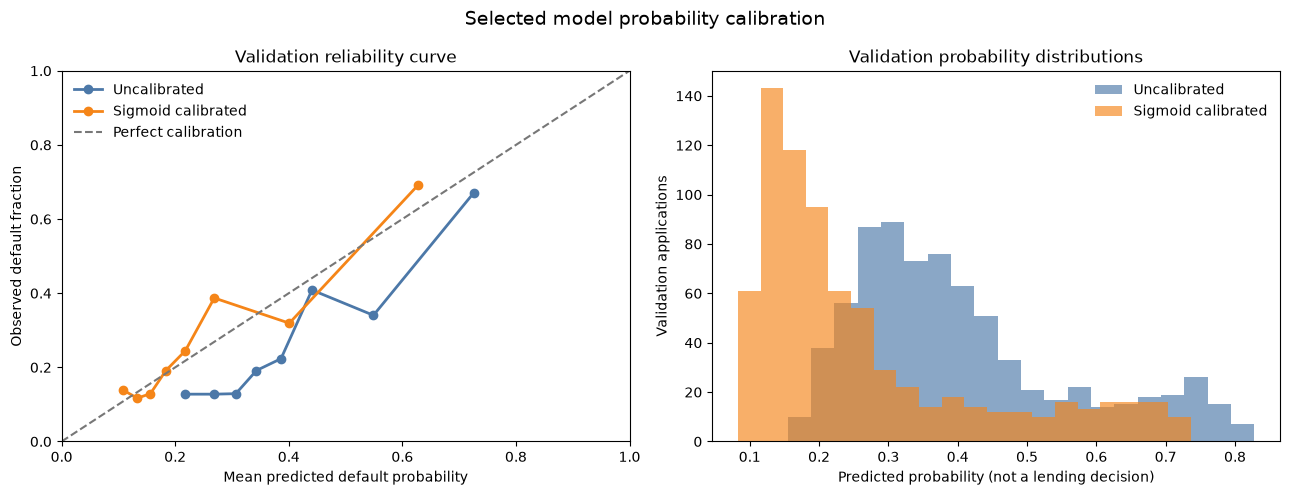

In [4]:
calibration_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
calibrated_candidate = CalibratedClassifierCV(
    estimator=selected_base_model,
    method="sigmoid",
    cv=calibration_cv,
    n_jobs=1,
)
calibrated_candidate.fit(X_train, y_train)
raw_validation_probabilities = selected_base_model.predict_proba(X_validation)[:, 1]
calibrated_validation_probabilities = calibrated_candidate.predict_proba(X_validation)[:, 1]
calibration_comparison = pd.DataFrame(
    [
        {"probabilities": "Uncalibrated", **probability_metrics(y_validation, raw_validation_probabilities)},
        {"probabilities": "Sigmoid calibrated", **probability_metrics(y_validation, calibrated_validation_probabilities)},
    ]
).set_index("probabilities")
print(f"Selected candidate: {selected_model_name}; sigmoid calibrator trained using training folds only.")
display(calibration_comparison.round(4))

calibrated_threshold_rows = []
for threshold in np.arange(0.05, 0.951, 0.005):
    labels_at_threshold = (calibrated_validation_probabilities >= threshold).astype("int8")
    calibrated_threshold_rows.append(
        {
            "threshold": threshold,
            "precision": precision_score(y_validation, labels_at_threshold, zero_division=0),
            "recall": recall_score(y_validation, labels_at_threshold, zero_division=0),
            "f1": f1_score(y_validation, labels_at_threshold, zero_division=0),
            "alerts": int(labels_at_threshold.sum()),
        }
    )
calibrated_threshold_table = pd.DataFrame(calibrated_threshold_rows)
calibrated_best_row = calibrated_threshold_table.sort_values(
    ["f1", "precision", "threshold"], ascending=[False, False, False]
).iloc[0]
decision_threshold = float(calibrated_best_row["threshold"])
print("Selected validation operating point after calibration:")
display(calibrated_best_row.to_frame("validation value").round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for probabilities, label, color in [
    (raw_validation_probabilities, "Uncalibrated", "#4C78A8"),
    (calibrated_validation_probabilities, "Sigmoid calibrated", "#F58518"),
]:
    observed_rate, mean_prediction = calibration_curve(
        y_validation, probabilities, n_bins=8, strategy="quantile"
    )
    axes[0].plot(mean_prediction, observed_rate, marker="o", linewidth=2, label=label, color=color)
axes[0].plot([0, 1], [0, 1], linestyle="--", color="#777777", label="Perfect calibration")
axes[0].set(xlim=(0, 1), ylim=(0, 1), xlabel="Mean predicted default probability", ylabel="Observed default fraction", title="Validation reliability curve")
axes[0].legend(frameon=False)
axes[1].hist(raw_validation_probabilities, bins=20, alpha=0.65, color="#4C78A8", label="Uncalibrated")
axes[1].hist(calibrated_validation_probabilities, bins=20, alpha=0.65, color="#F58518", label="Sigmoid calibrated")
axes[1].set(xlabel="Predicted probability (not a lending decision)", ylabel="Validation applications", title="Validation probability distributions")
axes[1].legend(frameon=False)
fig.suptitle("Selected model probability calibration", fontsize=14)
fig.tight_layout()
plt.show()

Sigmoid calibration learns a mapping from out-of-fold training predictions and does not use validation labels for fitting. The reliability curve and proper scoring rules indicate whether the calibrated probabilities better reflect the validation sample's outcome frequencies; calibration can improve probability interpretation without improving ranking. The operating threshold is selected from calibrated validation scores using F1, a statistical trade-off—not a business loss optimum. A lender would need explicit, reviewed costs of false positives and false negatives to set a decision rule.

## 5. Explain the selected model's feature behavior

Use permutation importance on the validation partition to measure how much shuffling each raw input degrades average precision. This is a global, model-dependent diagnostic; correlated predictors can share or dilute importance, and the same validation split has already been used for selection. It does not show causation, individual reasons, or feature fairness.

Top validation permutation importances (positive values indicate lower AP after shuffling):


,mean_average_precision_drop,standard_deviation
feature,,
debt_to_income_after_loan,0.1453,0.0130
requested_loan_to_annual_income,0.0334,0.0148
late_payments_last_12m,0.0228,0.0039
estimated_emi_inr,0.0184,0.0020
requested_loan_amount_inr,0.0130,0.0047
loan_tenure_months,0.0118,0.0016
monthly_net_income_inr,0.0096,0.0046
credit_utilization_ratio,0.0052,0.0059
savings_balance_inr,0.0040,0.0022


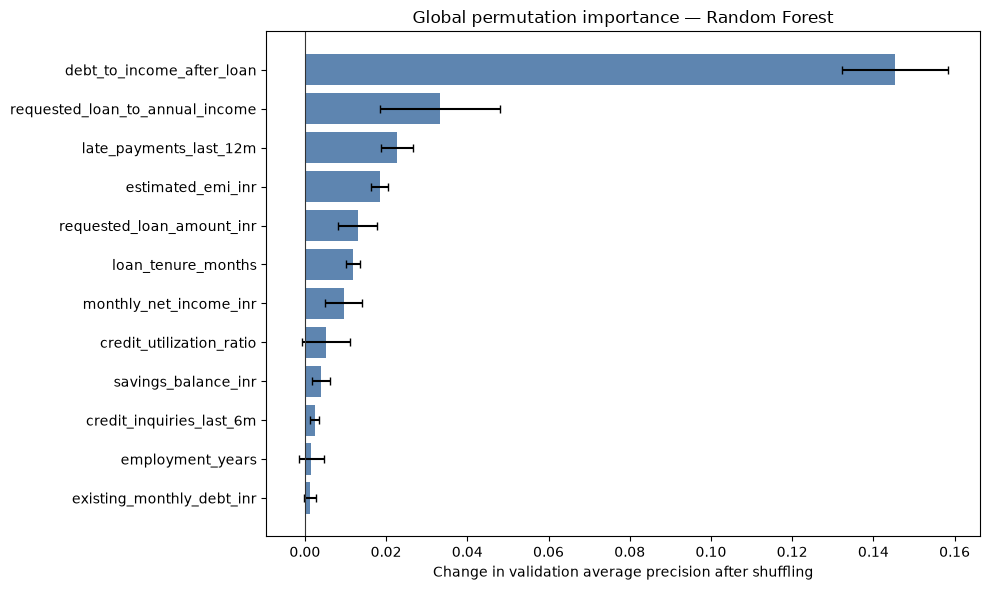

Interpret importance as predictive reliance within this sample, not causal influence or a valid individual explanation.


In [5]:
permutation_result = permutation_importance(
    selected_base_model,
    X_validation,
    y_validation,
    scoring="average_precision",
    n_repeats=3,
    random_state=RANDOM_STATE,
    n_jobs=1,
)
importance_table = pd.DataFrame(
    {
        "feature": feature_columns,
        "mean_average_precision_drop": permutation_result.importances_mean,
        "standard_deviation": permutation_result.importances_std,
    }
).sort_values("mean_average_precision_drop", ascending=False)
print("Top validation permutation importances (positive values indicate lower AP after shuffling):")
display(importance_table.head(12).set_index("feature").round(4))

top_importance = importance_table.head(12).sort_values("mean_average_precision_drop")
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(
    top_importance["feature"],
    top_importance["mean_average_precision_drop"],
    xerr=top_importance["standard_deviation"],
    color="#4C78A8",
    alpha=0.9,
    capsize=3,
)
ax.axvline(0, color="#333333", linewidth=0.8)
ax.set_xlabel("Change in validation average precision after shuffling")
ax.set_title(f"Global permutation importance — {selected_model_name}")
fig.tight_layout()
plt.show()

print("Interpret importance as predictive reliance within this sample, not causal influence or a valid individual explanation.")

Features with larger positive average-precision drops contribute more to the selected model's validation ranking in this sample. Small or negative scores can arise from sampling noise or redundant correlated inputs. This retrospective permutation diagnostic is not feature selection, an explanation of a specific person's score, a fairness review, or evidence that the feature is suitable for real credit decisions.

## 6. Refit on development data, evaluate once on the test set, and save

Model family, tuned hyperparameters, calibration method, and operating threshold are fixed using training and validation data. Now refit the selected calibrated pipeline using the combined development rows, evaluate the reserved test set once, and save the exact fitted pipeline together with its feature contract and validation-selected threshold.

Final selected model: Random Forest
Validation-selected threshold: 0.230
One-time held-out test results:


,test value
roc_auc,0.7335
average_precision,0.5175
brier_score,0.1737
log_loss,0.5242
decision_threshold,0.2300
precision_at_threshold,0.4377
recall_at_threshold,0.6923
f1_at_threshold,0.5363
alerts_at_threshold,329.0000
test_applications,750.0000


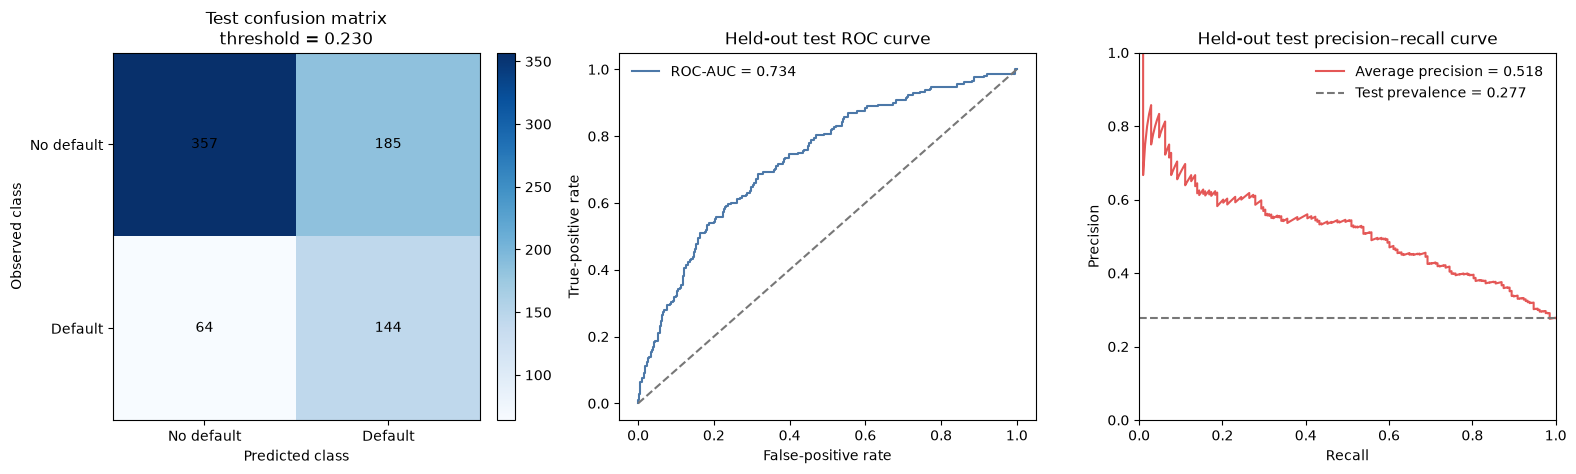

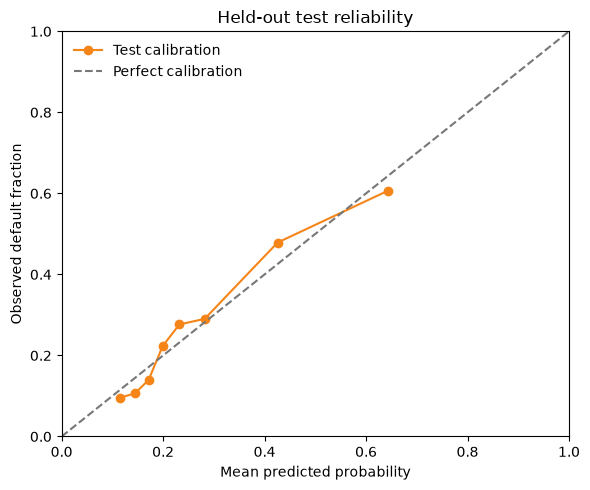

Saved selected fitted pipeline and metadata to: D:\GOURAB DAS\CODE\Git\FinSight AI\models\credit_risk_model.joblib
Provide raw predictor columns to the saved pipeline; calculate requested_loan_to_annual_income with the documented formula before prediction.


In [6]:
final_model = CalibratedClassifierCV(
    estimator=selected_search.best_estimator_,
    method="sigmoid",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE),
    n_jobs=1,
)
# The test rows are not passed into fit, model selection, calibration, or threshold selection.
final_model.fit(X_development, y_development)
test_probabilities = final_model.predict_proba(X_test)[:, 1]
test_predictions = (test_probabilities >= decision_threshold).astype("int8")
test_metrics = probability_metrics(y_test, test_probabilities)
test_metrics.update(
    {
        "decision_threshold": decision_threshold,
        "precision_at_threshold": precision_score(y_test, test_predictions, zero_division=0),
        "recall_at_threshold": recall_score(y_test, test_predictions, zero_division=0),
        "f1_at_threshold": f1_score(y_test, test_predictions, zero_division=0),
        "alerts_at_threshold": int(test_predictions.sum()),
        "test_applications": len(y_test),
    }
)
print(f"Final selected model: {selected_model_name}")
print(f"Validation-selected threshold: {decision_threshold:.3f}")
print("One-time held-out test results:")
display(pd.Series(test_metrics, name="test value").to_frame().round(4))

matrix = confusion_matrix(y_test, test_predictions, labels=[0, 1])
test_fpr, test_tpr, _ = roc_curve(y_test, test_probabilities)
test_precision_curve, test_recall_curve, _ = precision_recall_curve(y_test, test_probabilities)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.7))
image = axes[0].imshow(matrix, cmap="Blues")
axes[0].set_xticks([0, 1], labels=["No default", "Default"])
axes[0].set_yticks([0, 1], labels=["No default", "Default"])
axes[0].set(xlabel="Predicted class", ylabel="Observed class", title=f"Test confusion matrix\nthreshold = {decision_threshold:.3f}")
for row in range(2):
    for column in range(2):
        axes[0].text(column, row, f"{matrix[row, column]:,}", ha="center", va="center", color="black")
fig.colorbar(image, ax=axes[0], fraction=0.046, pad=0.04)
axes[1].plot(test_fpr, test_tpr, color="#4C78A8", label=f"ROC-AUC = {test_metrics['roc_auc']:.3f}")
axes[1].plot([0, 1], [0, 1], linestyle="--", color="#777777")
axes[1].set(xlabel="False-positive rate", ylabel="True-positive rate", title="Held-out test ROC curve")
axes[1].legend(frameon=False)
axes[2].plot(test_recall_curve, test_precision_curve, color="#E45756", label=f"Average precision = {test_metrics['average_precision']:.3f}")
axes[2].axhline(y_test.mean(), color="#777777", linestyle="--", label=f"Test prevalence = {y_test.mean():.3f}")
axes[2].set(xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 1), title="Held-out test precision–recall curve")
axes[2].legend(frameon=False)
fig.tight_layout()
plt.show()

test_calibration = calibration_curve(y_test, test_probabilities, n_bins=8, strategy="quantile")
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(test_calibration[1], test_calibration[0], marker="o", color="#F58518", label="Test calibration")
ax.plot([0, 1], [0, 1], linestyle="--", color="#777777", label="Perfect calibration")
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="Mean predicted probability", ylabel="Observed default fraction", title="Held-out test reliability")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

project_root = data_path.resolve().parents[2]
artifact_path = project_root / "models" / "credit_risk_model.joblib"
artifact_path.parent.mkdir(parents=True, exist_ok=True)
model_artifact = {
    "pipeline": final_model,
    "model_name": selected_model_name,
    "target_column": TARGET,
    "positive_label": 1,
    "decision_threshold": decision_threshold,
    "raw_feature_columns": raw_features,
    "model_input_columns": feature_columns,
    "engineered_features": {
        "requested_loan_to_annual_income": "requested_loan_amount_inr / (12 * monthly_net_income_inr)"
    },
    "excluded_fields": excluded_fields,
    "calibration_method": "sigmoid; 3-fold stratified cross-validation",
    "random_state": RANDOM_STATE,
    "training_and_validation_rows": len(y_development),
    "selected_hyperparameters": selected_search.best_params_,
    "validation_model_selection_metric": "average precision",
    "threshold_selection_metric": "F1 score on calibrated validation probabilities",
    "test_metrics": test_metrics,
    "data_note": "Synthetic educational dataset; not validated for real lending decisions.",
}
joblib.dump(model_artifact, artifact_path)
print(f"Saved selected fitted pipeline and metadata to: {artifact_path.resolve()}")
print("Provide raw predictor columns to the saved pipeline; calculate requested_loan_to_annual_income with the documented formula before prediction.")

The reported test metrics and curves are final estimates from the reserved, stratified holdout; no choices are revised from these results. Precision and recall are measured at the threshold frozen from calibrated validation scores, while ROC-AUC, average precision, Brier score, and log loss evaluate ranking or probabilities independently of that operating point. The saved artifact includes the refitted calibrated pipeline, exact validation threshold, feature definitions, exclusions, and test metrics. It is an experiment artifact—not a deployment approval or a financial decision rule.

## Supervised Modeling Summary

### Q&A

- **Which models were compared?** Logistic Regression and Random Forest were tuned alongside scikit-learn Histogram Gradient Boosting. XGBoost is not installed or declared in the project environment, so no additional dependency was introduced.
- **How were model choice and threshold selected?** Validation average precision ranks model discrimination, with Brier score as a tie-breaker. Sigmoid calibration is fitted using training folds. An F1-based classification threshold is selected using calibrated validation predictions, never the test set.
- **What is the final test result?** The validation-selected Random Forest achieved test ROC-AUC 0.7335, average precision 0.5175, Brier score 0.1737, and log loss 0.5242. At the validation-selected 0.230 threshold, test precision was 0.4377, recall 0.6923, and F1 0.5363 (329 of 750 applications flagged).
- **Was the fitted pipeline saved?** Yes: `models/credit_risk_model.joblib`, with the calibrated pipeline, validation-selected threshold, inference feature contract, engineered-feature definition, exclusions, and test metadata. A five-row load-and-predict smoke test returned finite probabilities.

### Data Analysis Key Findings

- Stratified 70/15/15 partitions contain 3,500 training, 750 validation, and 750 test applications. The selected Random Forest led validation average precision (0.5595) versus 0.5320 for Logistic Regression and 0.5131 for Histogram Gradient Boosting; the prevalence baseline scored 0.2773.
- Sigmoid calibration of the selected model improved validation Brier score from 0.1877 to 0.1709 and log loss from 0.5610 to 0.5203. Its test results remain estimates from one held-out split, not a guarantee of future performance.
- Evaluation includes a prior-probability baseline, ROC-AUC, average precision, Brier score, log loss, threshold-dependent precision/recall/F1 and alert counts, calibration, confusion matrix, and global permutation importance.
- The source dataset is synthetic and provides no evidence of real-world default performance, fairness, causal behavior, or safe lending decisions. Several included loan/credit fields also need timestamp and availability verification before any real-world use.

### Insights or Next Steps

- Review the verified validation/test results, calibration, model importance, and the business costs of missed defaults versus false alarms before choosing an operating threshold for any use case.
- Before use beyond this exercise, verify decision-time feature availability and lawful use, run appropriate independent temporal/population and fairness validations, and confirm the saved artifact's inference interface. Do not treat probabilities or class labels as automated credit decisions.